##punto 2.2

Muestras de entrenamiento: 210
Muestras de prueba: 90

--- RESULTADOS DE ACCURACY ---
k =  1 | Accuracy Train: 1.0000 (100.00%) | Accuracy Test: 0.9333 (93.33%)
k =  5 | Accuracy Train: 0.9571 (95.71%) | Accuracy Test: 0.9556 (95.56%)
k = 15 | Accuracy Train: 0.9571 (95.71%) | Accuracy Test: 0.9333 (93.33%)


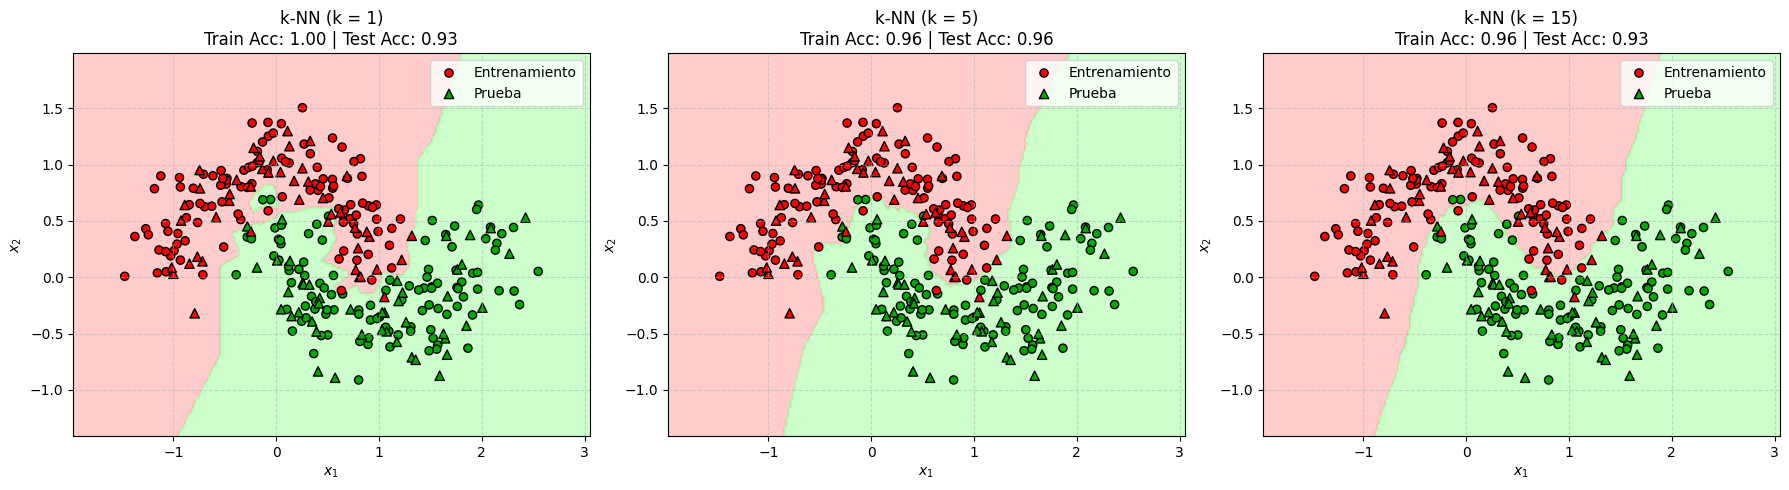

In [1]:
# ==============================================================================
# PUNTO 2.2: Clasificación por k-NN en dataset Make Moons
# ==============================================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# 1. Generación del conjunto de datos
X, y = make_moons(n_samples=300, noise=0.20, random_state=42)

# 2. División train (70%) / test (30%) estratificada
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

print(f"Muestras de entrenamiento: {X_train.shape[0]}")
print(f"Muestras de prueba: {X_test.shape[0]}\n")

# 3. Entrenamiento y evaluación para k in {1, 5, 15}
k_values = [1, 5, 15]
accuracies = {}

print("--- RESULTADOS DE ACCURACY ---")
for k in k_values:
    clf = KNeighborsClassifier(n_neighbors=k)
    clf.fit(X_train, y_train)

    acc_train = accuracy_score(y_train, clf.predict(X_train))
    acc_test = accuracy_score(y_test, clf.predict(X_test))

    accuracies[k] = (acc_train, acc_test)
    print(f"k = {k:2d} | Accuracy Train: {acc_train:.4f} ({acc_train*100:.2f}%) | Accuracy Test: {acc_test:.4f} ({acc_test*100:.2f}%)")

# 4. Graficar regiones de decisión
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA'])
cmap_bold = ListedColormap(['#FF0000', '#00AA00'])

# Definir la malla (grid) para evaluar las regiones de decisión
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                     np.arange(y_min, y_max, 0.02))

for idx, k in enumerate(k_values):
    clf = KNeighborsClassifier(n_neighbors=k)
    clf.fit(X_train, y_train)

    # Predicción en toda la malla
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # Dibujar fronteras de decisión
    axes[idx].contourf(xx, yy, Z, cmap=cmap_light, alpha=0.6)

    # Dibujar puntos de entrenamiento
    scatter_train = axes[idx].scatter(
        X_train[:, 0], X_train[:, 1], c=y_train, cmap=cmap_bold,
        edgecolor='k', s=35, label='Entrenamiento'
    )
    # Dibujar puntos de prueba
    scatter_test = axes[idx].scatter(
        X_test[:, 0], X_test[:, 1], c=y_test, cmap=cmap_bold,
        marker='^', edgecolor='k', s=45, label='Prueba'
    )

    acc_tr, acc_te = accuracies[k]
    axes[idx].set_title(f"k-NN (k = {k})\nTrain Acc: {acc_tr:.2f} | Test Acc: {acc_te:.2f}", fontsize=12)
    axes[idx].set_xlabel("$x_1$")
    axes[idx].set_ylabel("$x_2$")
    axes[idx].legend(loc='upper right')
    axes[idx].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

##Punto 3.3

In [2]:
# ==============================================================================
# PUNTO 3.3: Verificación con scikit-learn en Python
# ==============================================================================

import numpy as np
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Definición de vectores de etiquetas reales y predichas
y_true = np.array([0, 0, 0, 0, 1, 1, 1, 1, 1, 1])
y_pred = np.array([0, 1, 0, 0, 1, 0, 1, 1, 0, 1])

# 1. Matriz de confusión
cm = confusion_matrix(y_true, y_pred)
tn, fp, fn, tp = cm.ravel()

# 2. Cálculo de métricas
acc = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred)
rec = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

# Impresión formateada de resultados
print("=== MATRIZ DE CONFUSIÓN ===")
print(cm)
print(f"TN: {tn}, FP: {fp}, FN: {fn}, TP: {tp}\n")

print("=== MÉTRICAS DE EVALUACIÓN ===")
print(f"Accuracy  : {acc:.4f} (Esperado: 0.7000)")
print(f"Precision : {prec:.4f} (Esperado: 0.8000)")
print(f"Recall    : {rec:.4f} (Esperado: 0.6667)")
print(f"F1-Score  : {f1:.4f} (Esperado: 0.7273)")

=== MATRIZ DE CONFUSIÓN ===
[[3 1]
 [2 4]]
TN: 3, FP: 1, FN: 2, TP: 4

=== MÉTRICAS DE EVALUACIÓN ===
Accuracy  : 0.7000 (Esperado: 0.7000)
Precision : 0.8000 (Esperado: 0.8000)
Recall    : 0.6667 (Esperado: 0.6667)
F1-Score  : 0.7273 (Esperado: 0.7273)
